# Fraud Detection – Exploratory Data Analysis (EDA)
This notebook performs an exploratory analysis of the Credit Card Fraud Detection dataset.  
It covers distribution analysis, correlations, scaling impact, and feature importance.

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
sns.set(style="whitegrid")

plt.rcParams["figure.figsize"] = (6,4)

os.makedirs("reports/eda", exist_ok=True)

df = pd.read_csv("../data/raw/creditcard.csv")
df.head()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Basic Data Information
We inspect data types, missing values, and basic statistics.

In [21]:
df.info()
df.describe()
df.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

## 3. Class Distribution (Fraud vs Non-Fraud)
The dataset is heavily imbalanced. Visualizing it helps understand the challenge ahead.

Counts:
 Class
0    284315
1       492
Name: count, dtype: int64

Ratio:
 Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64


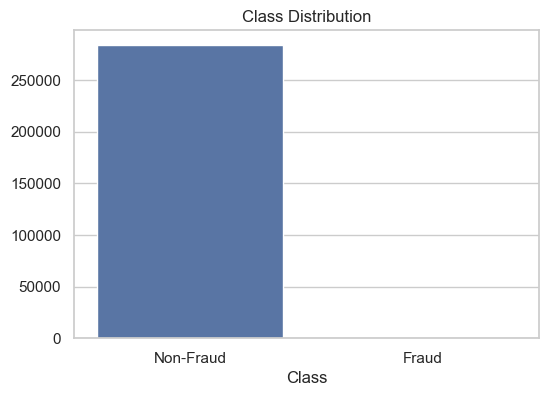

In [33]:
class_counts = df["Class"].value_counts()
class_ratio = df["Class"].value_counts(normalize=True)

print("Counts:\n", class_counts)
print("\nRatio:\n", class_ratio)

sns.barplot(x=class_counts.index, y=class_counts.values)
plt.title("Class Distribution")
plt.xticks([0,1], ["Non-Fraud", "Fraud"])
plt.savefig("reports/eda/class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


## 4. Correlation Matrix
We examine correlations between each feature and the target variable (`Class`).


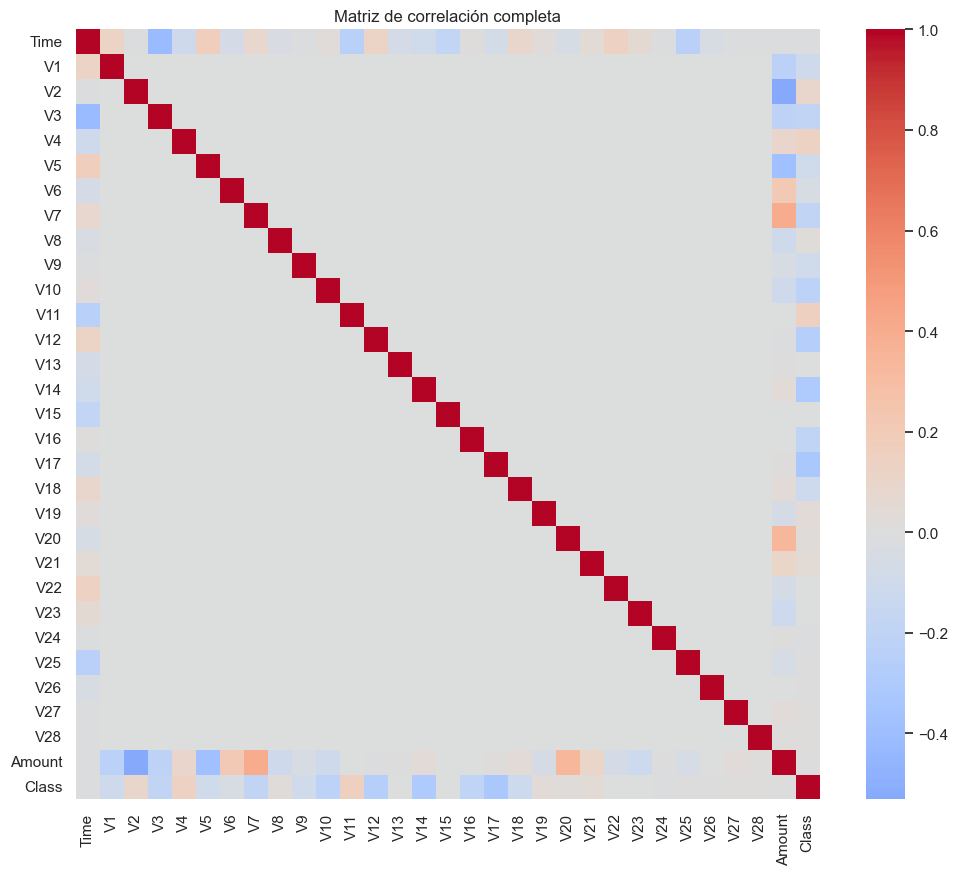

Class    1.000000
V17      0.326481
V14      0.302544
V12      0.260593
V10      0.216883
V16      0.196539
V3       0.192961
V7       0.187257
V11      0.154876
V4       0.133447
V18      0.111485
V1       0.101347
V9       0.097733
V5       0.094974
V2       0.091289
Name: Class, dtype: float64

<Figure size 600x400 with 0 Axes>

In [34]:

corr = df.corr()

plt.figure(figsize=(12,10))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Matriz de correlación completa")
plt.show()

corr = df.corr()["Class"].abs().sort_values(ascending=False)
plt.savefig("reports/eda/correlation_heatmap_top10.png", dpi=300, bbox_inches="tight")
corr.head(15)


## 5. Selecting Top Correlated Features
We pick a set of high-correlation features to explore deeper.


In [24]:
top_corr_vars = corr.index[1:10]  # skip Class itself
top_corr_vars

Index(['V17', 'V14', 'V12', 'V10', 'V16', 'V3', 'V7', 'V11', 'V4'], dtype='object')

## 5.1 Distribution Comparison by Class

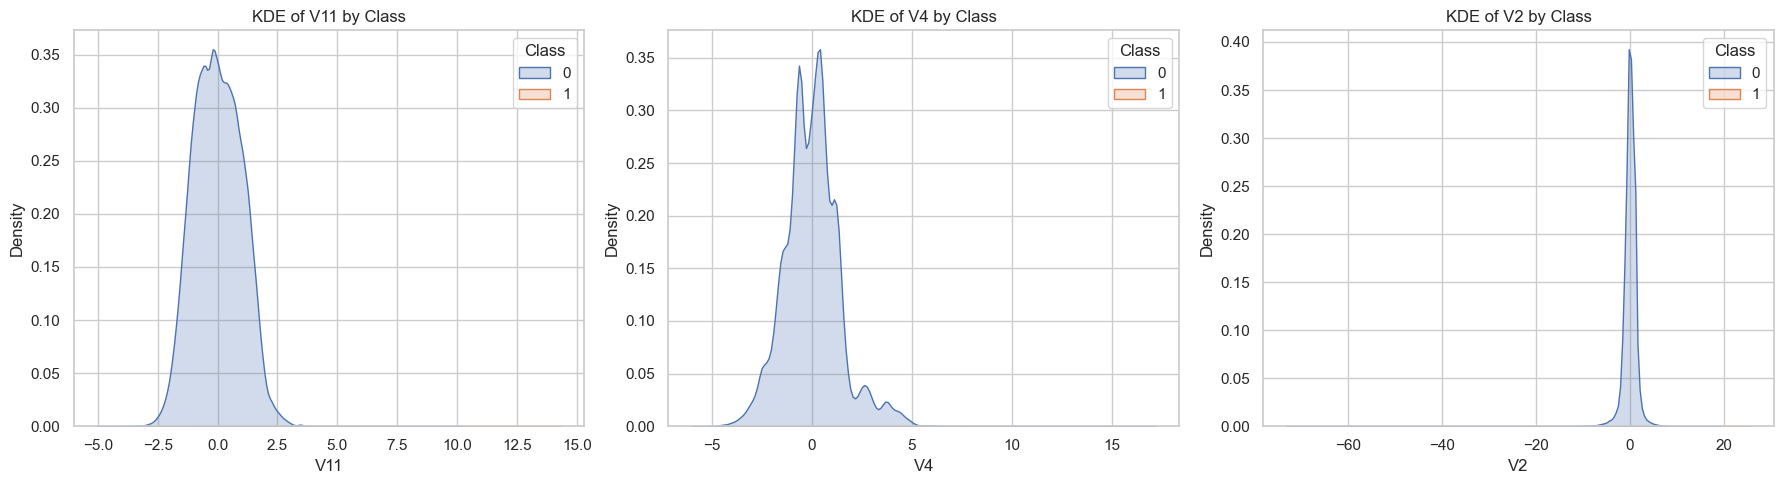

In [35]:
# choose features manually or dynamically
features_to_plot = ["V11", "V4", "V2"] # ramdomly chosen for illustration

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(features_to_plot):
    sns.kdeplot(
        data=df,
        x=col,
        hue="Class",
        fill=True,
        ax=axes[i]
    )
    axes[i].set_title(f"KDE of {col} by Class")
plt.savefig("reports/eda/distribution_rf_features.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

## 5.2 Boxplots by Class

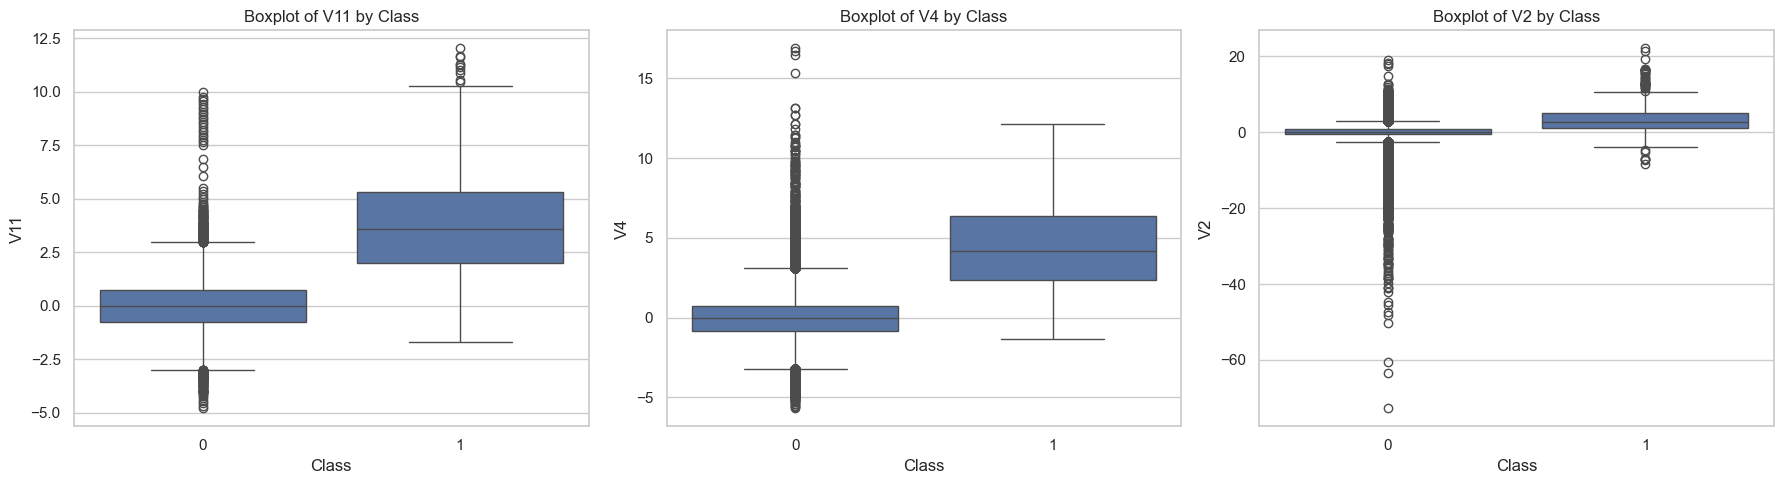

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(features_to_plot):
    sns.boxplot(
        data=df,
        x="Class",
        y=col,
        ax=axes[i]
    )
    axes[i].set_title(f"Boxplot of {col} by Class")

plt.tight_layout()
plt.savefig("reports/eda/boxplots_rf_features.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Feature Distributions for Fraud vs Non-Fraud
We compare the density distributions of the most relevant variables.

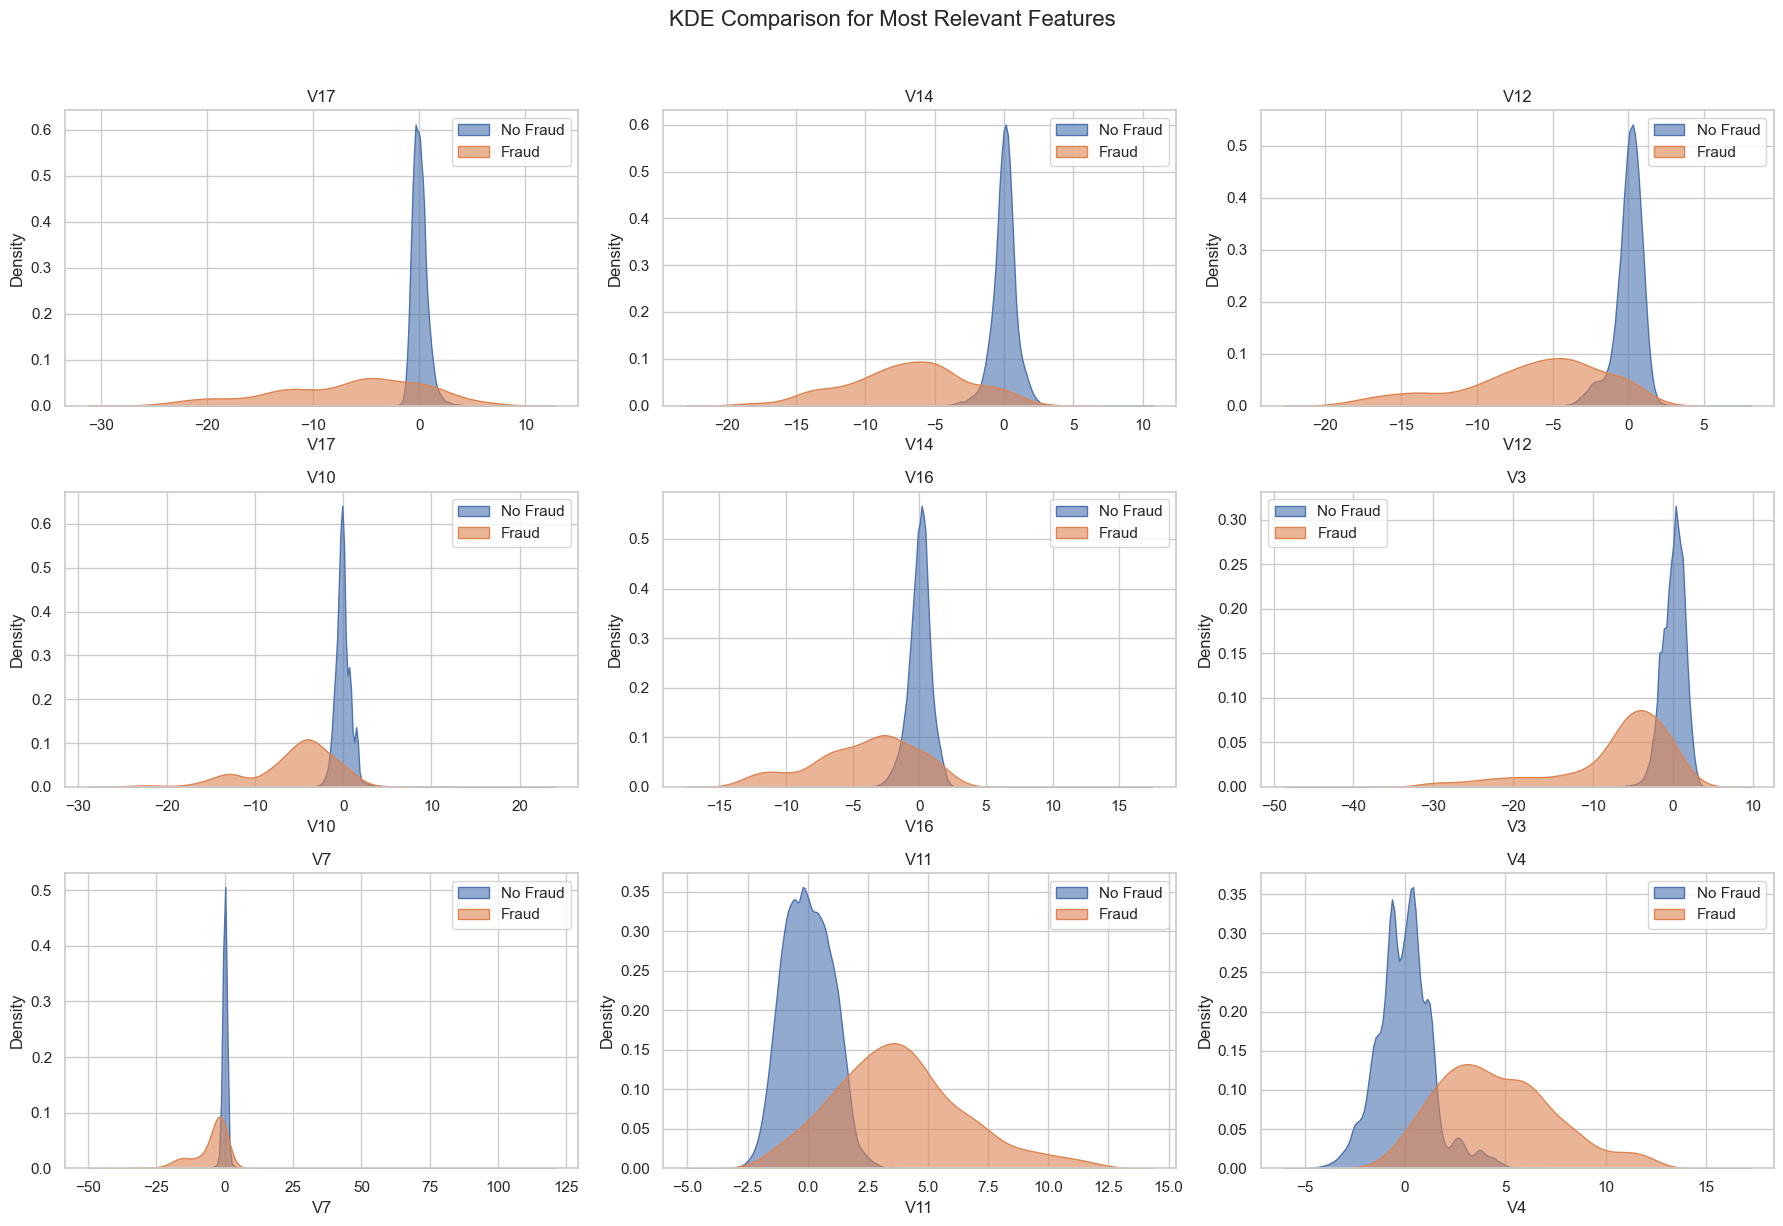

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

vars_to_plot = top_corr_vars
num_vars = len(vars_to_plot)
cols = 3
rows = (num_vars + cols - 1) // cols

plt.figure(figsize=(18, rows * 4))

for i, col in enumerate(vars_to_plot, 1):
    ax = plt.subplot(rows, cols, i)
    sns.kdeplot(
        data=df[df["Class"]==0], x=col,
        fill=True, common_norm=False, alpha=0.6, label="No Fraud", ax=ax
    )
    sns.kdeplot(
        data=df[df["Class"]==1], x=col,
        fill=True, common_norm=False, alpha=0.6, label="Fraud", ax=ax
    )
    ax.set_title(col)
    ax.legend()

plt.suptitle("KDE Comparison for Most Relevant Features", fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig("reports/eda/features_distribution_fraudVSnon-fraud.png", dpi=300, bbox_inches="tight")

plt.show()


## 7. Feature Importance (Random Forest)
Correlation alone is not enough.  
Here we train a quick Random Forest to estimate feature importance.


In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Class"])
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42
)
rf.fit(X_train, y_train)

importances = pd.Series(rf.feature_importances_, index=X.columns)
importances.sort_values(ascending=False).head(15)


V14       0.172755
V4        0.115382
V10       0.111231
V12       0.093417
V17       0.092719
V3        0.064234
V11       0.058795
V16       0.051311
V2        0.028824
V7        0.025840
V9        0.019088
V21       0.018189
V19       0.012253
Amount    0.011777
V20       0.011611
dtype: float64

## 8. Plot Top Feature Importances
Visualizing the Random Forest importances helps us select features for modeling.


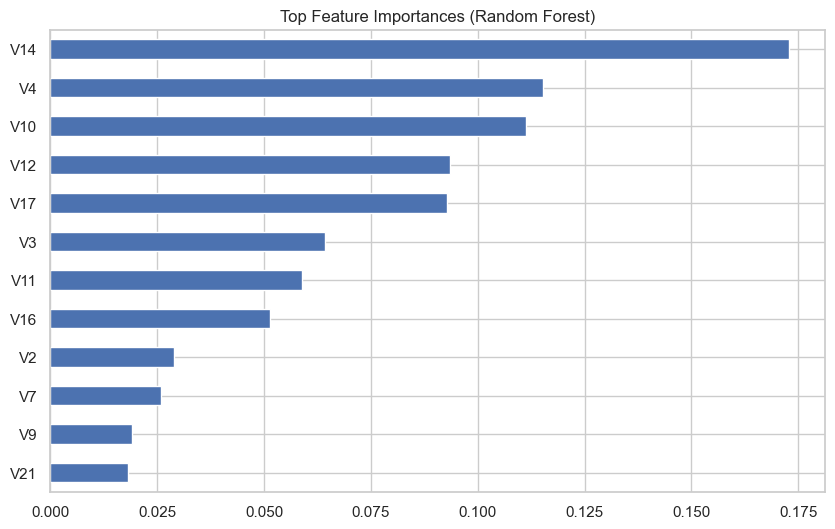

In [38]:
plt.figure(figsize=(10,6))
importances.sort_values().tail(12).plot(kind="barh")
plt.title("Top Feature Importances (Random Forest)")
plt.savefig("reports/eda/top_features_importance_random_forest.png", dpi=300, bbox_inches="tight")

plt.show()


# 9 Distribution Plots (KDE) for Top RF Features

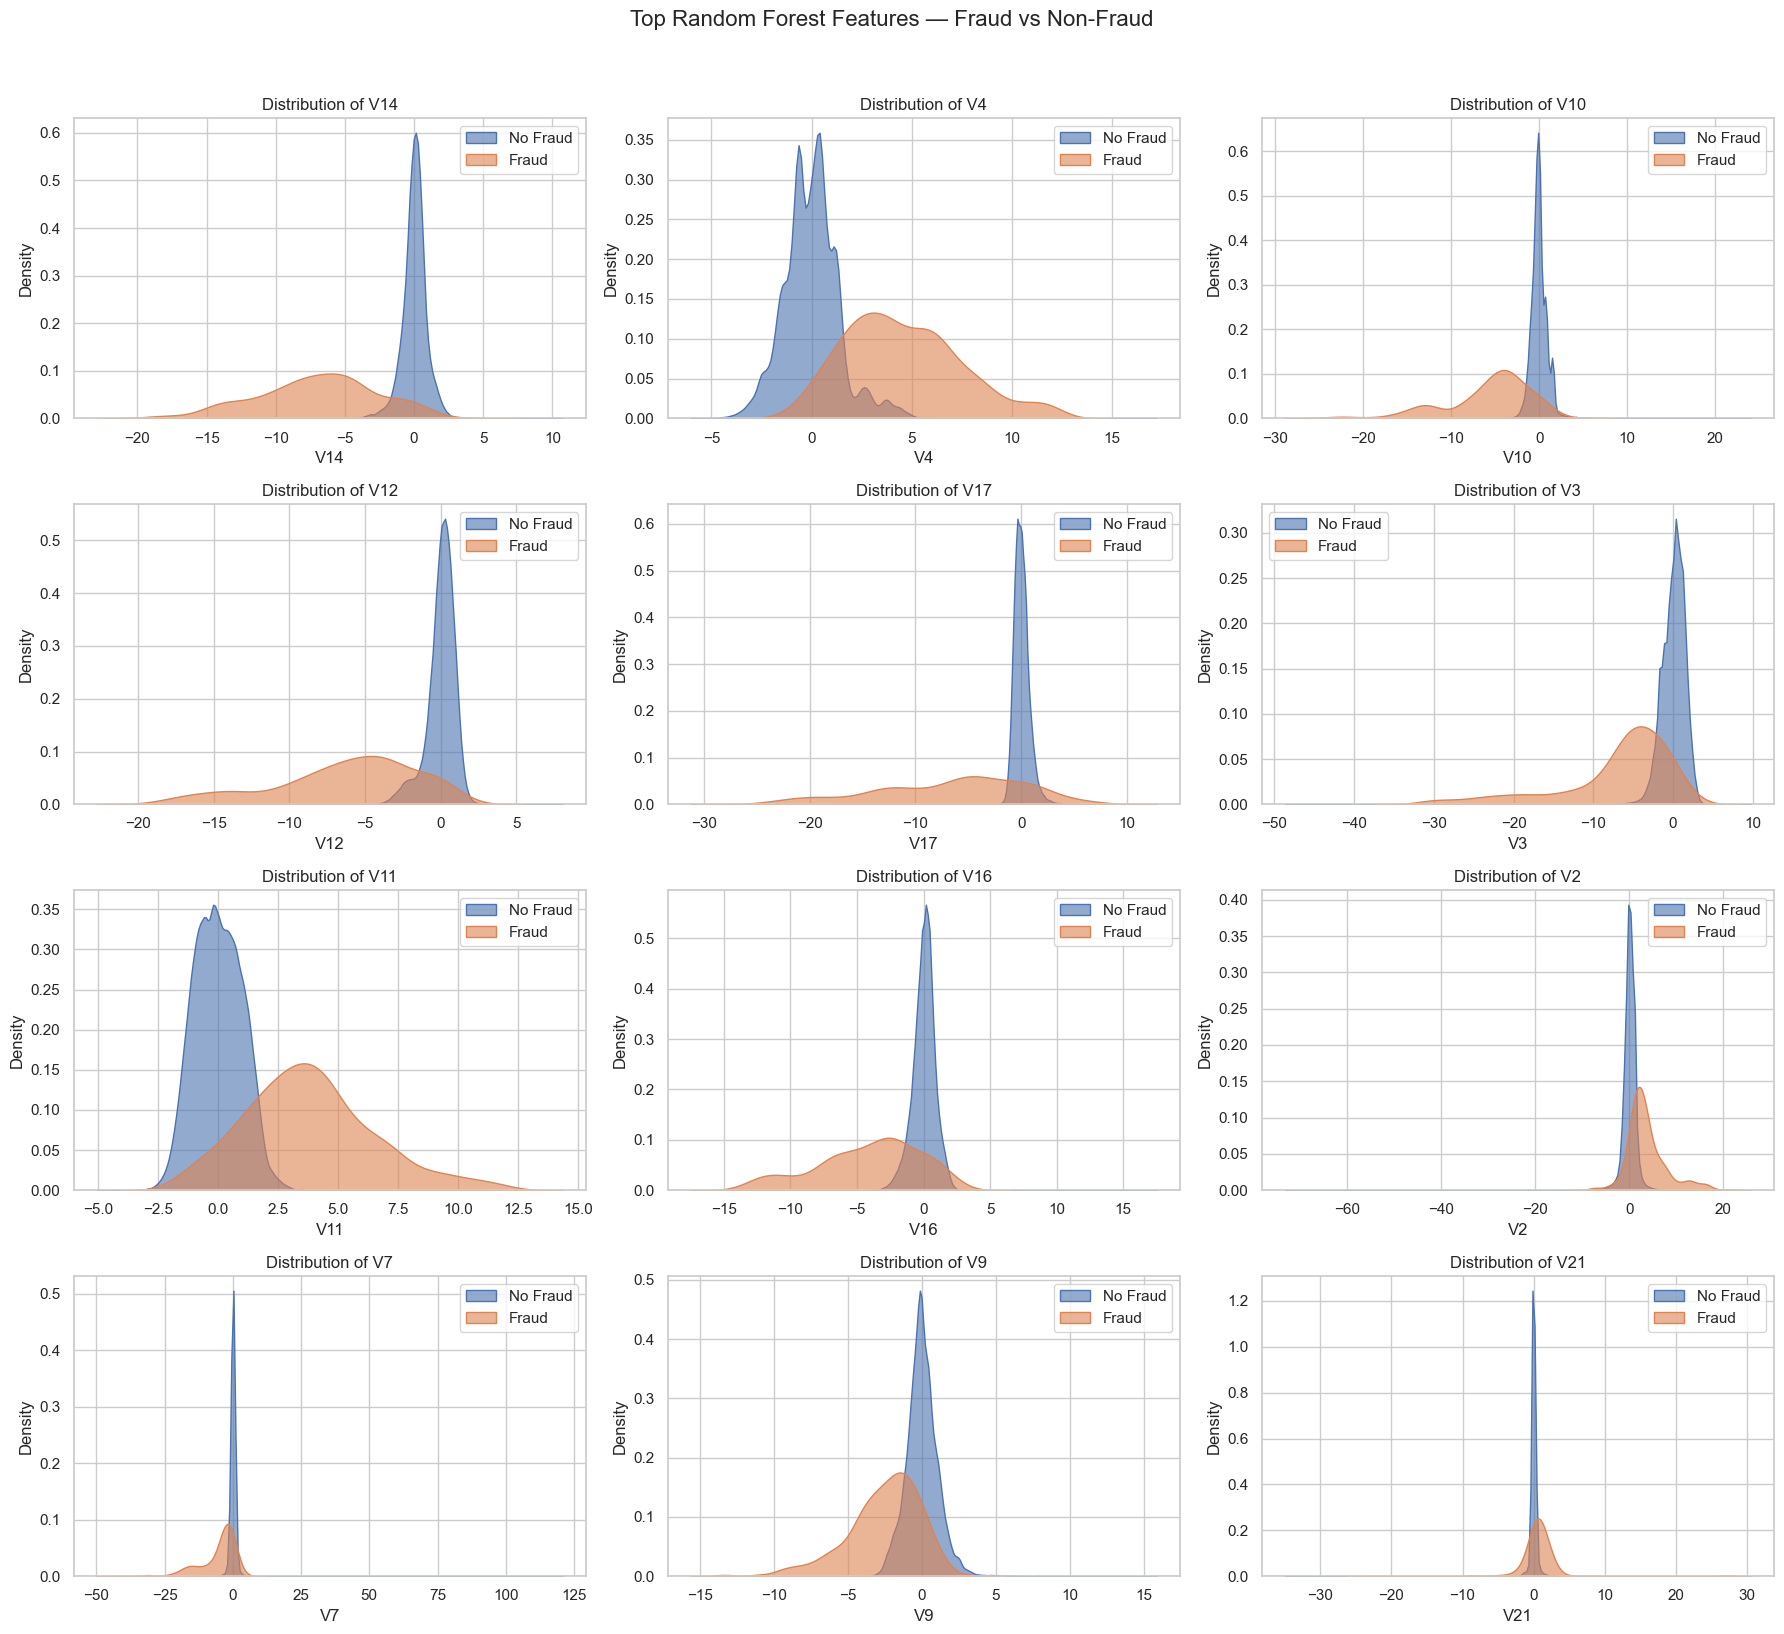

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

vars_to_plot =  importances.sort_values(ascending=False).head(12).index.tolist()

num_vars = len(vars_to_plot)

cols = 3
rows = (num_vars + cols - 1) // cols

plt.figure(figsize=(18, rows * 4))

for i, col in enumerate(vars_to_plot, 1):
    ax = plt.subplot(rows, cols, i)

    sns.kdeplot(
        data=df[df["Class"] == 0],
        x=col,
        fill=True,
        alpha=0.6,
        common_norm=False,
        label="No Fraud",
        ax=ax
    )

    sns.kdeplot(
        data=df[df["Class"] == 1],
        x=col,
        fill=True,
        alpha=0.6,
        common_norm=False,
        label="Fraud",
        ax=ax
    )

    ax.set_title(f"Distribution of {col}")
    ax.legend()

plt.suptitle("Top Random Forest Features — Fraud vs Non-Fraud", fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig("reports/eda/top_rf_features_distribution_fraudVSnon-fraud.png", dpi=300, bbox_inches="tight")
plt.show()


# 9. Distribution of amount and time
thoose are the only variables understable, so it could be handy to look ath the data

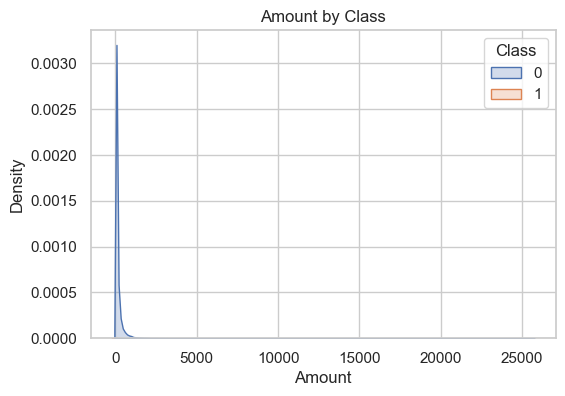

In [41]:
# ## Amount Distribution by Class

fig, ax = plt.subplots(figsize=(6,4))
sns.kdeplot(data=df, x="Amount", hue="Class", fill=True)
plt.title("Amount by Class")
plt.savefig("reports/eda/amount_kde.png", dpi=300, bbox_inches="tight")
plt.show()


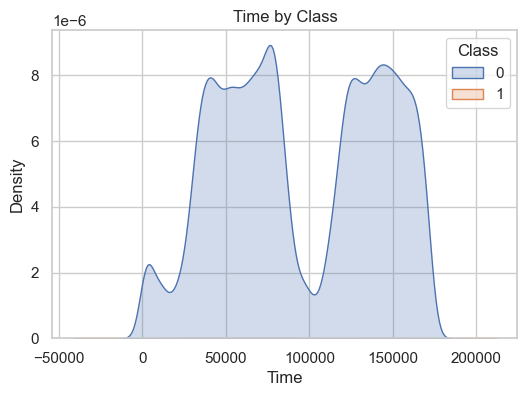

In [42]:
# ## Time Distribution by Class

fig, ax = plt.subplots(figsize=(6,4))
sns.kdeplot(data=df, x="Time", hue="Class", fill=True)
plt.title("Time by Class")
plt.savefig("reports/eda/time_kde.png", dpi=300, bbox_inches="tight")
plt.show()

# 10. EDA Conclusions

### Key Findings:
- The dataset is *highly imbalanced* (only ~0.17% fraud cases).
- Correlation analysis alone is insufficient; fraud patterns are subtle.
- Random Forest importance identifies meaningful features.
- Fraud transactions show very different distributions in some PCA components.

### Next Steps:
- Apply data balancing techniques (SMOTE, undersampling).
- Train models with tuned hyperparameters.
- Use cross-validation to ensure stability.